# Proyek 3 — GIS: Pemetaan Fasilitas Kesehatan di Kecamatan Ratu Agung Kota Bengkulu


In [31]:
!pip -q install osmnx geopandas folium
import osmnx as ox
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Konfigurasi server alternatif dan cache agar stabil
ox.settings.use_cache = True
ox.settings.log_console = True
ox.settings.overpass_endpoint = "https://overpass.kumi.systems/api/interpreter"
ox.settings.timeout = 180

# Target wilayah spesifik
PLACE = "Ratu Agung, Bengkulu, Indonesia"

## 1. Ambil batas wilayah dan fasilitas dari OpenStreetMap

In [32]:
print(f"Mencari titik koordinat untuk: {PLACE}...")
lat, lon = ox.geocode(PLACE)
print(f"Koordinat ditemukan: Lat {lat}, Lon {lon}")

print("Mengambil data fasilitas kesehatan dari Overpass API berdasarkan radius...")
tags = {"amenity": ["hospital", "clinic", "doctors", "pharmacy", "dentist"]}

# Menggunakan features_from_point dengan radius 3000 meter (3 km)
raw_places = ox.features_from_point((lat, lon), tags=tags, dist=3000)

# Perbaikan aman untuk mengatasi error MultiIndex NaN ke int di versi terbaru
if not raw_places.empty:
    if isinstance(raw_places.index, pd.MultiIndex):
        raw_places.index = pd.MultiIndex.from_tuples(
            [tuple(str(val) for val in idx) for idx in raw_places.index],
            names=raw_places.index.names
        )
    else:
        raw_places.index = raw_places.index.astype(str)

    places = raw_places.reset_index(drop=False)
    if "geometry" in places.columns:
        places = places[places.geometry.notnull()].copy()
        places['geometry'] = places['geometry'].apply(lambda geom: geom.buffer(0) if geom and not geom.is_valid else geom)
else:
    places = gpd.GeoDataFrame(columns=list(tags.keys()) + ["name", "geometry"], crs="EPSG:4326")

# Membuat boundary titik pusat untuk visualisasi
from shapely.geometry import Point
boundary = gpd.GeoDataFrame(geometry=[Point(lon, lat)], crs="EPSG:4326")
boundary["display_name"] = PLACE

display(boundary[["display_name", "geometry"]])
print("Jumlah Fasilitas Kesehatan Ditemukan:", len(places))
if not places.empty:
    print(places.columns.tolist())
    display(places[[c for c in ["name", "amenity", "geometry"] if c in places.columns]].head())
else:
    print("Tidak ada fasilitas kesehatan yang ditemukan dengan tag tersebut di area ini.")

Mencari titik koordinat untuk: Ratu Agung, Bengkulu, Indonesia...
Koordinat ditemukan: Lat -3.7952488, Lon 102.2698356
Mengambil data fasilitas kesehatan dari Overpass API berdasarkan radius...


,display_name,geometry
0,"Ratu Agung, Bengkulu, Indonesia",POINT (102.26984 -3.79525)


Jumlah Fasilitas Kesehatan Ditemukan: 18
['element', 'id', 'geometry', 'addr:city', 'addr:street', 'amenity', 'name', 'operator:type', 'source', 'brand', 'brand:wikidata', 'dispensing', 'healthcare', 'building', 'building:condition', 'operator', 'operator:en', 'operator:id', 'operator:wikidata', 'addr:full', 'emergency', 'building:foundation', 'building:levels', 'building:roof', 'building:structure', 'building:walls', 'office', 'website']


,name,amenity,geometry
0,Apotek Nita,pharmacy,POINT (102.27311 -3.801)
1,Apotek Keluarga,pharmacy,POINT (102.27496 -3.79429)
2,Apotik Berkat,pharmacy,POINT (102.26686 -3.79825)
3,Apotik Kompas,pharmacy,POINT (102.26418 -3.80141)
4,Puskesmas,clinic,POINT (102.26629 -3.80856)


## 2. Ringkasan kategori fasilitas

In [ ]:
if "amenity" not in places.columns:
    raise ValueError("Tag amenity tidak ditemukan. Periksa respons OpenStreetMap dan dokumentasi OSMnx.")
summary = places["amenity"].fillna("unknown").value_counts().head(15).sort_values()
plt.figure(figsize=(9,6)); summary.plot(kind="barh"); plt.title(f"15 kategori amenitas terbanyak — {PLACE}"); plt.xlabel("Jumlah objek OSM"); plt.tight_layout(); plt.show()
display(summary.sort_values(ascending=False).rename("jumlah_objek").to_frame())

## 3. Peta fasilitas (titik) dan jaringan jalan

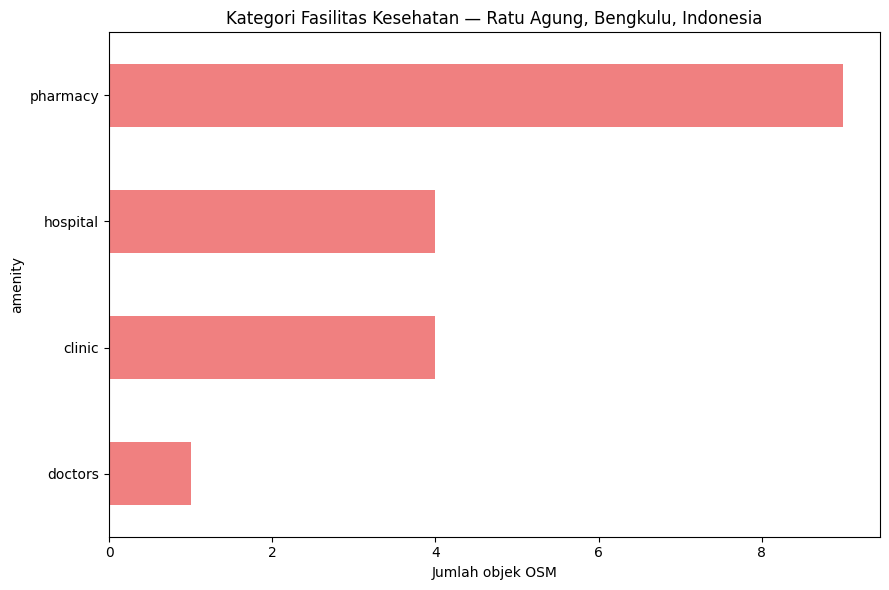

,jumlah_objek
amenity,
pharmacy,9
clinic,4
hospital,4
doctors,1


In [33]:
if "amenity" not in places.columns or places.empty:
    print("Data amenitas kosong, ringkasan tidak dapat dibuat.")
else:
    summary = places["amenity"].fillna("unknown").value_counts().head(15).sort_values()
    plt.figure(figsize=(9, 6))
    summary.plot(kind="barh", color="lightcoral")
    plt.title(f"Kategori Fasilitas Kesehatan — {PLACE}")
    plt.xlabel("Jumlah objek OSM")
    plt.tight_layout()
    plt.show()
    display(summary.sort_values(ascending=False).rename("jumlah_objek").to_frame())

## 4. Peta Fasilitas Kesehatan (Titik) dan Jaringan Jalan

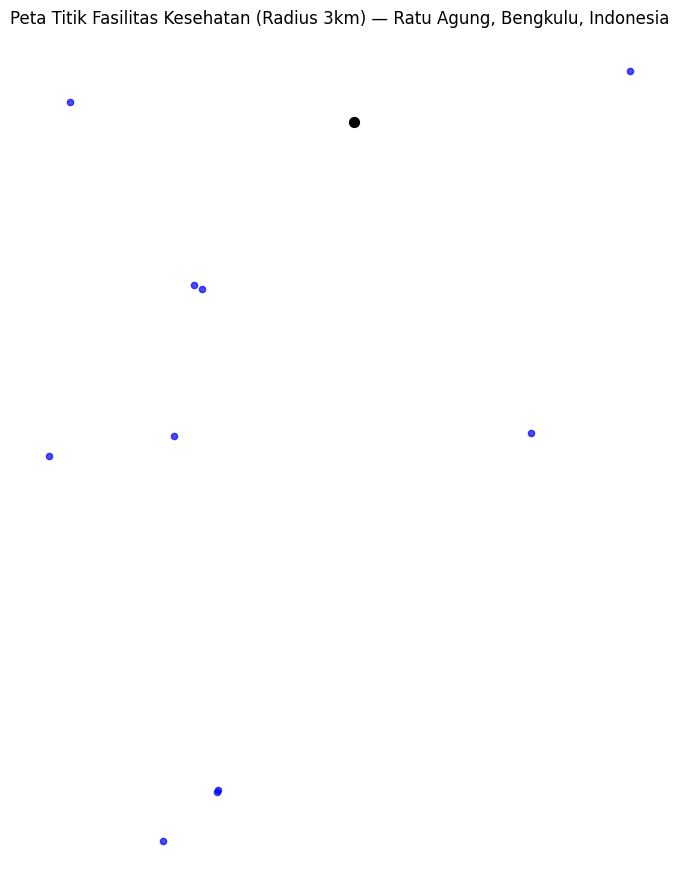

Node jaringan: 3896 | edge: 9162


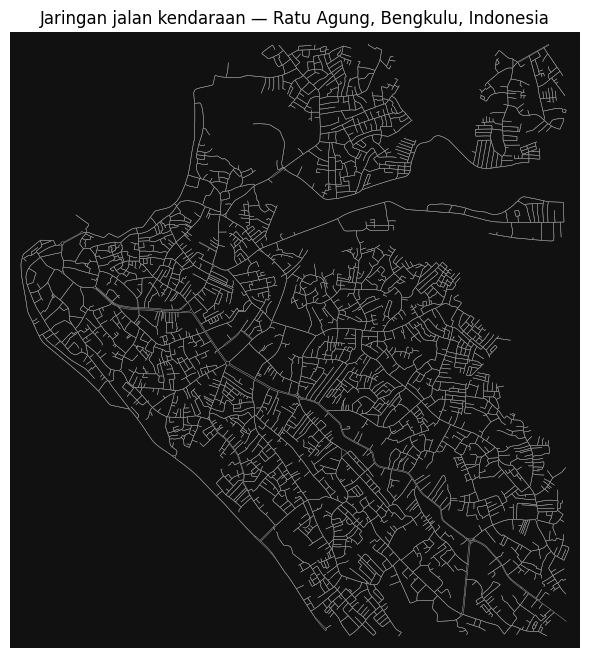

In [34]:
if not places.empty:
    points = places[places.geometry.geom_type.isin(["Point"])].copy()
    if points.crs is None:
        points = points.set_crs("EPSG:4326")
    points = points.to_crs("EPSG:4326")

    fig, ax = plt.subplots(figsize=(9, 9))
    boundary.to_crs("EPSG:4326").plot(ax=ax, color="black", markersize=50, label="Pusat")
    if not points.empty:
        points.plot(ax=ax, markersize=20, color="blue", alpha=0.7)
    ax.set_title(f"Peta Titik Fasilitas Kesehatan (Radius 3km) — {PLACE}")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

# Mengambil jaringan jalan kendaraan berdasarkan titik dan radius yang sama (3000 meter)
G = ox.graph_from_point((lat, lon), dist=3000, network_type="drive", simplify=True)
print("Node jaringan:", len(G.nodes), "| edge:", len(G.edges))
fig, ax = ox.plot_graph(G, node_size=0, edge_linewidth=0.35, show=False, close=False)
plt.title(f"Jaringan jalan kendaraan — {PLACE}")
plt.show()

## Catatan interpretasi dan lisensi
OSM adalah data peta kolaboratif; objek yang tidak tercatat bukan berarti fasilitas itu tidak ada. Cantumkan atribusi © OpenStreetMap contributors dan lisensi ODbL saat membagikan peta/data.

## 5. Simpan Hasil Tabel

In [35]:
if 'summary' in locals() and not summary.empty:
    summary.sort_values(ascending=False).to_csv("ringkasan_kesehatan_ratu_agung.csv", header=["jumlah_objek"])
    print("Tabel ringkasan kesehatan berhasil disimpan sebagai ringkasan_kesehatan_ratu_agung.csv")
else:
    print("Tidak ada data ringkasan untuk disimpan.")

Tabel ringkasan kesehatan berhasil disimpan sebagai ringkasan_kesehatan_ratu_agung.csv
